# AI-Powered Industrial Defect Detection — Part 1: Model Training

**Goal:** classify casting product images as **OK** or **DEFECTIVE** using TensorFlow/Keras.

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then run the cells top to bottom.

| Step | What happens |
|---|---|
| 1 | Setup: GPU check, Google Drive (to save models) |
| 2 | Download the dataset from Kaggle |
| 3 | Explore the data |
| 4 | Build the data pipeline + augmentation (OpenCV preprocessing for later use in Flask) |
| 5 | Baseline CNN (built from scratch) |
| 6 | MobileNetV2 transfer learning + fine-tuning |
| 7 | Evaluation: metrics, confusion matrix, threshold tuning, model comparison |
| 8 | Grad-CAM explainability |
| 9 | Inference speed + save everything for the Flask app |

## 1. Setup

In [ ]:
import os, glob, json, time, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
import keras
from keras import layers

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Mount Google Drive so trained models and reports survive after the Colab session ends
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/defect-detection'
MODEL_DIR = os.path.join(PROJECT_DIR, 'models')
REPORT_DIR = os.path.join(PROJECT_DIR, 'reports')
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)
print("Saving outputs to:", PROJECT_DIR)

Mounted at /content/drive
Saving outputs to: /content/drive/MyDrive/defect-detection


## 2. Download the dataset
Dataset: **Real-life Industrial Dataset of Casting Product** (Kaggle). `kagglehub` downloads public datasets directly.

If the download asks for login, create an API token on kaggle.com (*Settings → API → Create New Token*) and add it in Colab's **🔑 Secrets** panel as `KAGGLE_USERNAME` and `KAGGLE_KEY`.

In [ ]:
!pip install -q kagglehub
import kagglehub

DATA_ROOT = kagglehub.dataset_download("ravirajsinh45/real-life-industrial-dataset-of-casting-product")
print("Downloaded to:", DATA_ROOT)

# Locate the train/test folders (the archive has nested folders)
train_dirs = [d for d in glob.glob(os.path.join(DATA_ROOT, '**', 'train'), recursive=True)
              if os.path.isdir(os.path.join(d, 'def_front'))]
TRAIN_DIR = train_dirs[0]
TEST_DIR = os.path.join(os.path.dirname(TRAIN_DIR), 'test')
print("Train:", TRAIN_DIR)
print("Test: ", TEST_DIR)

Using Colab cache for faster access to the 'real-life-industrial-dataset-of-casting-product' dataset.
Downloaded to: /kaggle/input/real-life-industrial-dataset-of-casting-product
Train: /kaggle/input/real-life-industrial-dataset-of-casting-product/casting_data/casting_data/train
Test:  /kaggle/input/real-life-industrial-dataset-of-casting-product/casting_data/casting_data/test


## 3. Explore the data

train | ok_front  | 2875 images
train | def_front | 3758 images
test  | ok_front  | 262 images
test  | def_front | 453 images


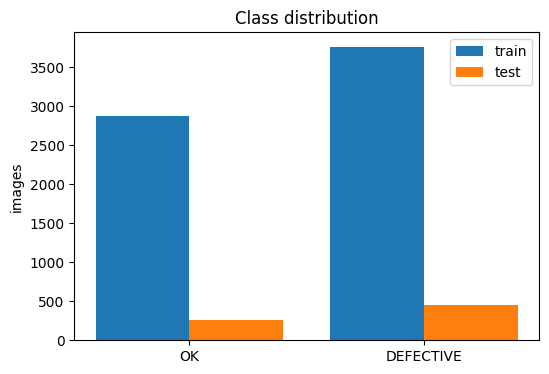

Original image shape: (300, 300, 3)


In [ ]:
CLASS_NAMES = ['ok_front', 'def_front']    # label 0 = OK, label 1 = DEFECTIVE
DISPLAY_NAMES = ['OK', 'DEFECTIVE']

counts = {}
for split, d in [('train', TRAIN_DIR), ('test', TEST_DIR)]:
    for c in CLASS_NAMES:
        counts[(split, c)] = len(os.listdir(os.path.join(d, c)))
for k, v in counts.items():
    print(f"{k[0]:5s} | {k[1]:9s} | {v} images")

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(2)
ax.bar(x - 0.2, [counts[('train', c)] for c in CLASS_NAMES], 0.4, label='train')
ax.bar(x + 0.2, [counts[('test', c)] for c in CLASS_NAMES], 0.4, label='test')
ax.set_xticks(x, DISPLAY_NAMES); ax.set_ylabel('images'); ax.set_title('Class distribution'); ax.legend()
plt.savefig(os.path.join(REPORT_DIR, 'class_distribution.png'), bbox_inches='tight'); plt.show()

sample = cv2.imread(glob.glob(os.path.join(TRAIN_DIR, 'ok_front', '*'))[0])
print("Original image shape:", sample.shape)

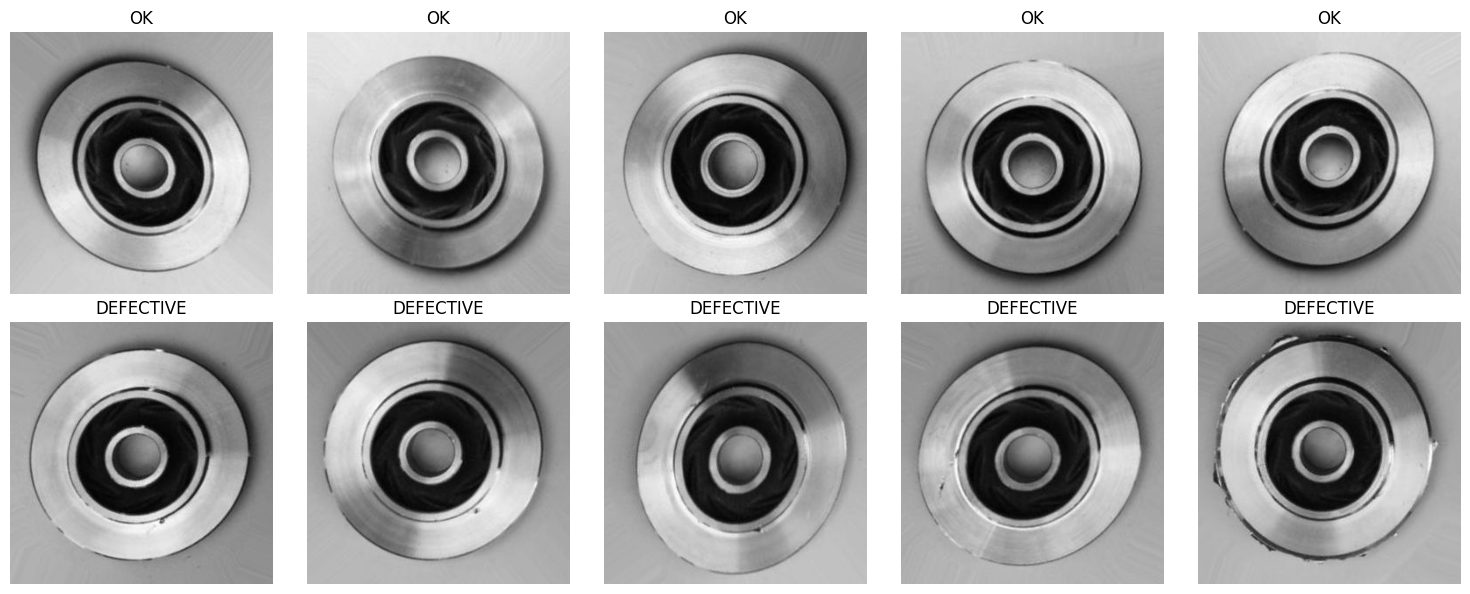

In [ ]:
# Show sample images from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for row, c in enumerate(CLASS_NAMES):
    files = random.sample(glob.glob(os.path.join(TRAIN_DIR, c, '*')), 5)
    for col, f in enumerate(files):
        img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
        axes[row, col].imshow(img); axes[row, col].axis('off')
        axes[row, col].set_title(DISPLAY_NAMES[row])
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, 'samples.png'), bbox_inches='tight'); plt.show()

## 4. Data pipeline + preprocessing
- Images are resized to **224×224** and loaded as 3-channel RGB (pretrained models expect 3 channels).
- 20% of the training folder is held out for **validation**; the **test** folder is used only at the end.
- Pixel scaling happens *inside* each model, so the Flask app can feed raw 0–255 RGB images.

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_raw, val_raw = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=CLASS_NAMES, label_mode='binary', color_mode='rgb',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, validation_split=0.2,
    subset='both', seed=SEED)
test_raw = keras.utils.image_dataset_from_directory(
    TEST_DIR, class_names=CLASS_NAMES, label_mode='binary', color_mode='rgb',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)
test_paths = test_raw.file_paths

train_ds = train_raw.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_raw.cache().prefetch(AUTOTUNE)
test_ds = test_raw.cache().prefetch(AUTOTUNE)

# Class weights: give the smaller class more importance during training
n_ok, n_def = counts[('train', 'ok_front')], counts[('train', 'def_front')]
total = n_ok + n_def
class_weight = {0: total / (2 * n_ok), 1: total / (2 * n_def)}
print("Class weights:", class_weight)

Found 6633 files belonging to 2 classes.
Using 5307 files for training.
Using 1326 files for validation.
Found 715 files belonging to 2 classes.
Class weights: {0: 1.1535652173913042, 1: 0.8825172964342736}


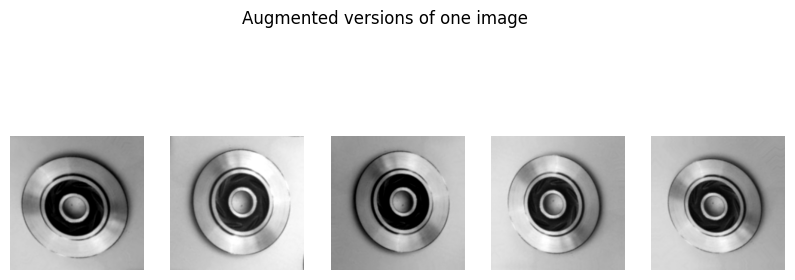

In [ ]:
# Data augmentation (only active during training)
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
    layers.RandomContrast(0.1),
], name='augmentation')

# Preview augmentation on one image
images, _ = next(iter(train_raw))
plt.figure(figsize=(10, 4))
for i in range(5):
    aug = data_augmentation(images[:1], training=True)
    plt.subplot(1, 5, i + 1); plt.imshow(np.clip(aug[0].numpy(), 0, 255).astype('uint8')); plt.axis('off')
plt.suptitle('Augmented versions of one image'); plt.show()

In [ ]:
# OpenCV preprocessing — the same steps the Flask app will use for uploaded images / webcam frames
def preprocess_cv2(image_bgr):
    """BGR image (from cv2.imread or a webcam frame) -> float32 batch of shape (1, 224, 224, 3)."""
    img = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
    return np.expand_dims(img.astype('float32'), axis=0)

def load_image(path):
    return preprocess_cv2(cv2.imread(path))

print(load_image(test_paths[0]).shape)

(1, 224, 224, 3)


In [ ]:
# Shared helpers
METRICS = ['accuracy', keras.metrics.Precision(name='precision'),
           keras.metrics.Recall(name='recall'), keras.metrics.AUC(name='auc')]

def get_callbacks(name):
    return [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7),
        keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR, f'{name}.keras'), monitor='val_loss', save_best_only=True),
    ]

def plot_history(histories, title, filename):
    hist = {}
    for h in histories:
        for k, v in h.history.items():
            hist.setdefault(k, []).extend(v)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ['accuracy', 'loss']):
        ax.plot(hist[metric], label='train'); ax.plot(hist['val_' + metric], label='validation')
        ax.set_title(f'{title} — {metric}'); ax.set_xlabel('epoch'); ax.legend()
    plt.savefig(os.path.join(REPORT_DIR, filename), bbox_inches='tight'); plt.show()

## 5. Baseline CNN (from scratch)

In [ ]:
def build_baseline_cnn():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inputs, outputs, name='baseline_cnn')

baseline = build_baseline_cnn()
baseline.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=METRICS)
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 56s 164ms/step - accuracy: 0.8050 - auc: 0.8795 - loss: 0.4392 - precision: 0.8520 - recall: 0.7893 - val_accuracy: 0.5897 - val_auc: 0.7496 - val_loss: 0.9238 - val_precision: 0.5897 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 55s 130ms/step - accuracy: 0.8966 - auc: 0.9593 - loss: 0.2564 - precision: 0.9345 - recall: 0.8770 - val_accuracy: 0.6765 - val_auc: 0.7714 - val_loss: 0.5981 - val_precision: 0.6467 - val_recall: 0.9949 - learning_rate: 0.0010
Epoch 3/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - accuracy: 0.9369 - auc: 0.9846 - loss: 0.1551 - precision: 0.9603 - recall: 0.9257 - val_accuracy: 0.5897 - val_auc: 0.5000 - val_loss: 7.4728 - val_precision: 0.5897 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 23s 136ms/step - accuracy: 0.9521 - auc: 0.9892 - loss: 0.1255 - precision: 0.9687 - recall: 0.9452 - val_accuracy: 0.9238 - val_auc: 0.9946 - val_loss: 

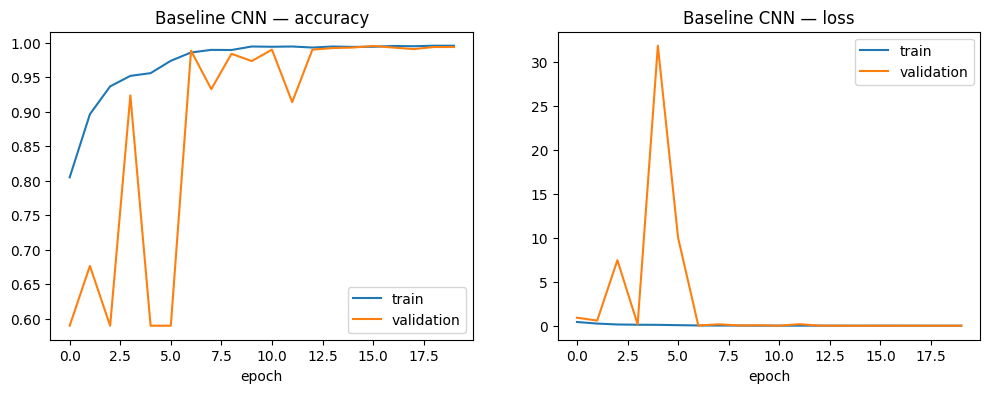

In [ ]:
hist_baseline = baseline.fit(train_ds, validation_data=val_ds, epochs=25,
                             class_weight=class_weight, callbacks=get_callbacks('baseline_cnn'))
plot_history([hist_baseline], 'Baseline CNN', 'baseline_history.png')

## 6. Transfer learning with MobileNetV2
**Stage 1:** freeze the pretrained base, train only the new classifier head.
**Stage 2:** unfreeze the top layers of the base and fine-tune with a very small learning rate.

In [ ]:
base_model = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
base_model.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1, name='rescale')(x)   # MobileNetV2 expects pixels in [-1, 1]
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name='gap')(x)
x = layers.Dropout(0.3, name='head_dropout')(x)
outputs = layers.Dense(1, activation='sigmoid', name='pred')(x)
tl_model = keras.Model(inputs, outputs, name='mobilenetv2_defect')

tl_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=METRICS)
tl_model.summary()

hist_tl1 = tl_model.fit(train_ds, validation_data=val_ds, epochs=10,
                        class_weight=class_weight, callbacks=get_callbacks('defect_model'))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_defect"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pred (Dense)                    │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 23s 103ms/step - accuracy: 0.8112 - auc: 0.9360 - loss: 0.4055 - precision: 0.8903 - recall: 0.8340 - val_accuracy: 0.9268 - val_auc: 0.9831 - val_loss: 0.2460 - val_precision: 0.9374 - val_recall: 0.9386 - learning_rate: 0.0010
Epoch 2/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 13s 76ms/step - accuracy: 0.9016 - auc: 0.9700 - loss: 0.2458 - precision: 0.9420 - recall: 0.8787 - val_accuracy: 0.9495 - val_auc: 0.9914 - val_loss: 0.1875 - val_precision: 0.9441 - val_recall: 0.9719 - learning_rate: 0.0010
Epoch 3/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 13s 77ms/step - accuracy: 0.9299 - auc: 0.9823 - loss: 0.1941 - precision: 0.9565 - recall: 0.9167 - val_accuracy: 0.9593 - val_auc: 0.9935 - val_loss: 0.1587 - val_precision: 0.9679 - val_recall: 0.9629 - learning_rate: 0.0010
Epoch 4/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 13s 76ms/step - accuracy: 0.9389 - auc: 0.9848 - loss: 0.1754 - precision: 0.9617 - recall: 0.9281 - val_accuracy: 0.9676 - val_auc: 0.9958 - val_loss: 0.1

In [ ]:
# Stage 2: fine-tune the last 30 layers of MobileNetV2
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:                     # keep BatchNorm frozen for stable fine-tuning
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

tl_model.compile(optimizer=keras.optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=METRICS)
start = len(hist_tl1.history['loss'])
hist_tl2 = tl_model.fit(train_ds, validation_data=val_ds, epochs=start + 15, initial_epoch=start,
                        class_weight=class_weight, callbacks=get_callbacks('defect_model'))
plot_history([hist_tl1, hist_tl2], 'MobileNetV2', 'mobilenet_history.png')

Epoch 11/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 22s 94ms/step - accuracy: 0.9702 - auc: 0.9954 - loss: 0.0851 - precision: 0.9843 - recall: 0.9670 - val_accuracy: 0.9902 - val_auc: 0.9994 - val_loss: 0.0379 - val_precision: 0.9898 - val_recall: 0.9936 - learning_rate: 1.0000e-05
Epoch 12/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 85ms/step - accuracy: 0.9849 - auc: 0.9982 - loss: 0.0457 - precision: 0.9908 - recall: 0.9822 - val_accuracy: 0.9910 - val_auc: 0.9995 - val_loss: 0.0310 - val_precision: 0.9911 - val_recall: 0.9936 - learning_rate: 1.0000e-05
Epoch 13/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.9879 - auc: 0.9982 - loss: 0.0375 - precision: 0.9932 - recall: 0.9852 - val_accuracy: 0.9940 - val_auc: 0.9997 - val_loss: 0.0250 - val_precision: 0.9949 - val_recall: 0.9949 - learning_rate: 1.0000e-05
Epoch 14/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 13s 80ms/step - accuracy: 0.9878 - auc: 0.9984 - loss: 0.0347 - precision: 0.9929 - recall: 0.9852 - val_accuracy: 0.9872 - val_auc: 0.9996 

## 7. Evaluation on the unseen test set
In quality inspection, **missing a defective part (false negative) is the costliest mistake**, so watch the **recall of the DEFECTIVE class** closely.

===== Baseline CNN (threshold=0.5) =====
              precision    recall  f1-score   support

          OK     1.0000    0.9809    0.9904       262
   DEFECTIVE     0.9891    1.0000    0.9945       453

    accuracy                         0.9930       715
   macro avg     0.9945    0.9905    0.9924       715
weighted avg     0.9931    0.9930    0.9930       715



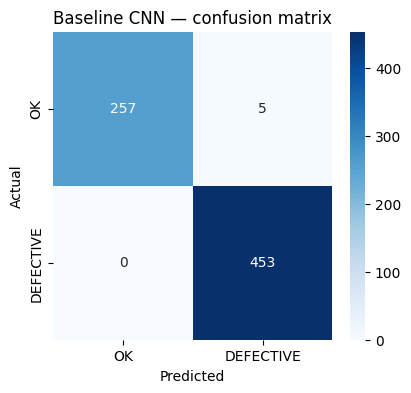

===== MobileNetV2 (threshold=0.5) =====
              precision    recall  f1-score   support

          OK     0.9924    0.9924    0.9924       262
   DEFECTIVE     0.9956    0.9956    0.9956       453

    accuracy                         0.9944       715
   macro avg     0.9940    0.9940    0.9940       715
weighted avg     0.9944    0.9944    0.9944       715



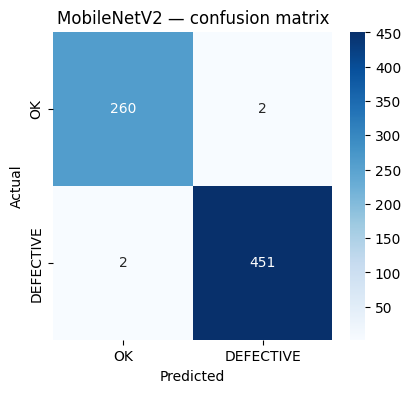

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_score, recall_score, f1_score, accuracy_score

y_true = np.concatenate([y.numpy() for _, y in test_ds]).ravel().astype(int)

def evaluate_model(model, name, threshold=0.5):
    probs = model.predict(test_ds, verbose=0).ravel()
    y_pred = (probs >= threshold).astype(int)
    print(f"===== {name} (threshold={threshold}) =====")
    print(classification_report(y_true, y_pred, target_names=DISPLAY_NAMES, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'{name} — confusion matrix')
    plt.savefig(os.path.join(REPORT_DIR, f'cm_{name.replace(" ", "_").lower()}.png'), bbox_inches='tight'); plt.show()
    return probs, {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (defective)': precision_score(y_true, y_pred),
        'Recall (defective)': recall_score(y_true, y_pred),
        'F1 (defective)': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, probs),
        'Params (M)': model.count_params() / 1e6,
    }

probs_base, res_base = evaluate_model(baseline, 'Baseline CNN')
probs_tl, res_tl = evaluate_model(tl_model, 'MobileNetV2')

In [ ]:
# Model comparison table (copy this into your report)
import pandas as pd
comparison = pd.DataFrame([res_base, res_tl]).set_index('Model').round(4)
comparison.to_csv(os.path.join(REPORT_DIR, 'model_comparison.csv'))
comparison

,Accuracy,Precision (defective),Recall (defective),F1 (defective),ROC-AUC,Params (M)
Model,,,,,,
Baseline CNN,0.9930,0.9891,1.0000,0.9945,0.9999,0.4234
MobileNetV2,0.9944,0.9956,0.9956,0.9956,0.9998,2.2593


In [ ]:
# Threshold tuning: lower threshold -> catch more defects, but more false alarms
rows = []
for t in np.arange(0.1, 0.95, 0.05):
    y_pred = (probs_tl >= t).astype(int)
    rows.append({'threshold': round(t, 2),
                 'recall (defective)': recall_score(y_true, y_pred),
                 'precision (defective)': precision_score(y_true, y_pred, zero_division=0),
                 'missed defects': int(((y_pred == 0) & (y_true == 1)).sum()),
                 'false alarms': int(((y_pred == 1) & (y_true == 0)).sum())})
thr_table = pd.DataFrame(rows)

# Pick the highest threshold that still keeps defect recall >= 99%, otherwise fall back to 0.5
ok_rows = thr_table[thr_table['recall (defective)'] >= 0.99]
BEST_THRESHOLD = float(ok_rows['threshold'].max()) if len(ok_rows) else 0.5
print("Chosen threshold:", BEST_THRESHOLD)
thr_table

Chosen threshold: 0.85


,threshold,recall (defective),precision (defective),missed defects,false alarms
0,0.10,1.000000,0.957717,0,20
1,0.15,0.997792,0.969957,1,14
2,0.20,0.997792,0.980477,1,9
3,0.25,0.995585,0.984716,2,7
4,0.30,0.995585,0.986871,2,6
5,0.35,0.995585,0.989035,2,5
6,0.40,0.995585,0.993392,2,3
7,0.45,0.995585,0.993392,2,3
8,0.50,0.995585,0.995585,2,2
9,0.55,0.995585,0.997788,2,1


3 misclassified out of 715


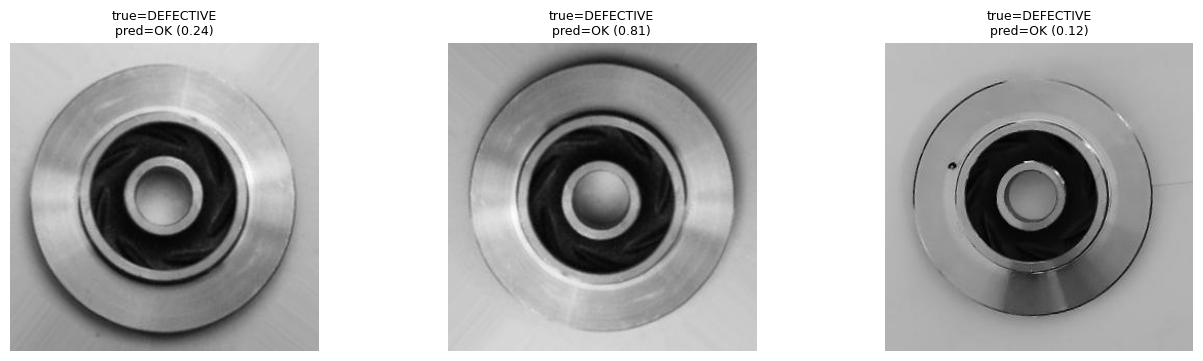

In [ ]:
# Look at the images the model got wrong
y_pred = (probs_tl >= BEST_THRESHOLD).astype(int)
wrong = np.where(y_pred != y_true)[0]
print(f"{len(wrong)} misclassified out of {len(y_true)}")
if len(wrong):
    n = min(len(wrong), 8)
    plt.figure(figsize=(16, 4))
    for i, idx in enumerate(wrong[:n]):
        img = cv2.cvtColor(cv2.imread(test_paths[idx]), cv2.COLOR_BGR2RGB)
        plt.subplot(1, n, i + 1); plt.imshow(img); plt.axis('off')
        plt.title(f"true={DISPLAY_NAMES[y_true[idx]]}\npred={DISPLAY_NAMES[y_pred[idx]]} ({probs_tl[idx]:.2f})", fontsize=9)
    plt.show()

## 8. Grad-CAM: where is the model looking?
The heatmap highlights the regions that pushed the model towards **DEFECTIVE**. On defective parts it should light up on the cracks / holes.

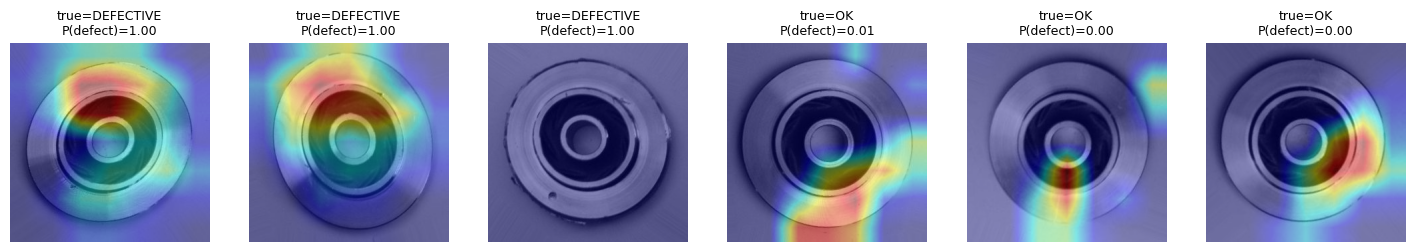

In [ ]:
def make_gradcam_heatmap(img_batch, model=None):
    """img_batch: float32 (1, 224, 224, 3) raw RGB 0-255. Returns (heatmap 0-1, defect probability)."""
    model = model or tl_model
    base = model.get_layer(base_model.name)
    conv_out = base(model.get_layer('rescale')(img_batch), training=False)   # last conv feature map (7x7x1280)
    with tf.GradientTape() as tape:
        tape.watch(conv_out)
        pred = model.get_layer('pred')(model.get_layer('gap')(conv_out))
        score = pred[:, 0]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))                         # importance of each channel
    heatmap = tf.reduce_sum(conv_out[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), float(pred[0, 0])

def overlay_heatmap(image_bgr, heatmap, alpha=0.4):
    h, w = image_bgr.shape[:2]
    hm = cv2.resize(heatmap, (w, h))
    hm = cv2.applyColorMap(np.uint8(255 * hm), cv2.COLORMAP_JET)
    return cv2.addWeighted(image_bgr, 1 - alpha, hm, alpha, 0)

# Show Grad-CAM for 3 defective and 3 OK test images
def_idx = [i for i in range(len(y_true)) if y_true[i] == 1][:3]
ok_idx = [i for i in range(len(y_true)) if y_true[i] == 0][:3]
plt.figure(figsize=(18, 6))
for i, idx in enumerate(def_idx + ok_idx):
    original = cv2.imread(test_paths[idx])
    heatmap, p = make_gradcam_heatmap(preprocess_cv2(original))
    out = cv2.cvtColor(overlay_heatmap(original, heatmap), cv2.COLOR_BGR2RGB)
    plt.subplot(1, 6, i + 1); plt.imshow(out); plt.axis('off')
    plt.title(f"true={DISPLAY_NAMES[y_true[idx]]}\nP(defect)={p:.2f}", fontsize=9)
plt.savefig(os.path.join(REPORT_DIR, 'gradcam_examples.png'), bbox_inches='tight'); plt.show()

## 9. Inference speed + save for the Flask app

In [ ]:
# Measure single-image inference time (what the Flask app will experience)
x = load_image(test_paths[0])
tl_model(x, training=False)                         # warm-up
times = []
for _ in range(50):
    t0 = time.perf_counter(); tl_model(x, training=False); times.append(time.perf_counter() - t0)
print(f"Average inference time: {np.mean(times) * 1000:.1f} ms per image (on {'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'})")

Average inference time: 180.4 ms per image (on GPU)


In [ ]:
# Save the final model + config the Flask app needs
tl_model.save(os.path.join(MODEL_DIR, 'defect_model.keras'))
config = {
    'img_size': list(IMG_SIZE),
    'class_names': DISPLAY_NAMES,          # index 0 = OK, 1 = DEFECTIVE
    'threshold': BEST_THRESHOLD,
    'base_model_layer': base_model.name,
    'test_metrics': {k: float(v) for k, v in res_tl.items() if k != 'Model'},
}
with open(os.path.join(MODEL_DIR, 'model_config.json'), 'w') as f:
    json.dump(config, f, indent=2)
print(json.dumps(config, indent=2))
print("\nSaved files:", os.listdir(MODEL_DIR))

{
  "img_size": [
    224,
    224
  ],
  "class_names": [
    "OK",
    "DEFECTIVE"
  ],
  "threshold": 0.85,
  "base_model_layer": "mobilenetv2_1.00_224",
  "test_metrics": {
    "Accuracy": 0.9944055944055944,
    "Precision (defective)": 0.9955849889624724,
    "Recall (defective)": 0.9955849889624724,
    "F1 (defective)": 0.9955849889624724,
    "ROC-AUC": 0.9997977857540064,
    "Params (M)": 2.259265
  }
}

Saved files: ['baseline_cnn.keras', 'model_config.json', 'defect_model.keras']


In [ ]:
# Sanity check: reload the saved model and predict one image
reloaded = keras.models.load_model(os.path.join(MODEL_DIR, 'defect_model.keras'))
p = float(reloaded(load_image(test_paths[0]), training=False)[0, 0])
label = DISPLAY_NAMES[int(p >= BEST_THRESHOLD)]
print(f"{os.path.basename(test_paths[0])}: {label}  (P(defect) = {p:.3f}, true = {DISPLAY_NAMES[y_true[0]]})")

cast_ok_0_10.jpeg: OK  (P(defect) = 0.012, true = OK)
